# Predictia performantei ofensive a jucatorilor

Notebookul combina statistici FBref cu istorice de absente Transfermarkt si compara regresia logistica cu padurea aleatoare. Tinta este 1 daca jucatorul inscrie, ofera assist sau are cel putin un sut pe poarta in meciul curent.

Predictorii folosesc toate aparitiile anterioare disponibile, adversarul, competitia, media istorica a minutelor ca estimare pre-meci si istoricul de absente raportate. Statisticile din meciul curent sunt folosite doar pentru tinta si explorarea descriptiva.

## 1. Date de intrare

Notebookul citeste meciurile si statisticile jucatorilor din `data/raw/fbref/fbref_player_match_stats.csv`, plus istoricul si profilurile Transfermarkt din `data/raw/transfermarkt/`. Ruleaza mai intai `extraction/data_scraper.ipynb`. Potrivirea Transfermarkt se face prin nume si aliasuri, iar numele ambigue nu sunt fortate.

In [10]:
from pathlib import Path
import re
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CWD = Path.cwd().resolve()
if CWD.name == "notebooks" and (CWD.parent / "README.md").exists():
    PROJECT_ROOT = CWD.parent
elif (CWD / "notebooks").is_dir() and (CWD / "README.md").exists():
    PROJECT_ROOT = CWD
else:
    candidates = [p for p in (CWD, *CWD.parents) if (p / "notebooks").is_dir() and (p / "README.md").exists()]
    if not candidates:
        raise RuntimeError("Deschide Jupyter din IAPD_project/ sau din directorul notebooks/.")
    PROJECT_ROOT = candidates[0]

DATA_ROOT = PROJECT_ROOT / "data"
MODEL_SOURCES = ["fbref"]  # Foloseste exportul FBref cu toate competitiile.
INPUT_FILES = {
    "fbref": DATA_ROOT / "raw" / "fbref" / "fbref_player_match_stats.csv",
}
TRANSFERMARKT_INJURIES_FILE = DATA_ROOT / "raw" / "transfermarkt" / "transfermarkt_player_injury_histories.csv"
TRANSFERMARKT_PROFILES_FILE = DATA_ROOT / "raw" / "transfermarkt" / "player_profiles.csv"
if not MODEL_SOURCES or any(source not in INPUT_FILES for source in MODEL_SOURCES):
    raise ValueError(f"Surse invalide: {MODEL_SOURCES}")
OUTPUT_DIR = DATA_ROOT / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Asociaza fiecare camp cu numele coloanei din setul de date ales.
# Exportul FBref contine aceste campuri comune pentru competitiile selectate.
COLUMN_MAP = {
    "player": "player",
    "match_date": "date",
    "minutes": "Min",
    "goals": "Gls",
    "assists": "Ast",
    "shots": "Sh",
    "shots_on_target": "SoT",
    "crosses": "Crs",
    "yellow_cards": "CrdY",
    "red_cards": "CrdR",
    # Optional: "match_id": "game_id",
}

In [11]:
frames = []
for source in MODEL_SOURCES:
    input_file = INPUT_FILES[source]
    if not input_file.exists():
        raise FileNotFoundError(
            f"Fisierul {input_file} lipseste. Ruleaza mai intai extraction/data_scraper.ipynb."
        )
    source_frame = pd.read_csv(input_file)
    source_frame["source"] = source
    frames.append(source_frame)

raw = pd.concat(frames, ignore_index=True, sort=False)
MIN_DATA_ROWS = 1_000
if len(raw) < MIN_DATA_ROWS:
    raise ValueError(f"Criteriul setului de date nu este indeplinit: {len(raw):,} randuri; sunt necesare cel putin {MIN_DATA_ROWS:,}.")
print(f"Incarcate {len(raw):,} randuri din sursele {', '.join(MODEL_SOURCES)}")
print("Randuri pe sursa:")
display(raw.groupby("source").size().rename("randuri").to_frame())
raw.head()


Incarcate 66,731 randuri din sursele fbref
Randuri pe sursa:


,randuri
source,
fbref,66731


,league,season,game,team,player,jersey_number,nation,pos,age,Min,...,Off,Crs,TklW,Int,OG,PKwon,PKcon,game_id,date,source
0,Champions League,2324,2023-09-19 Barcelona es-be Antwerp,Antwerp,Alhassan Yusuf,8,NGA,MF,23-063,30.0,...,0.0,1.0,1.0,0.0,0.0,NaN,NaN,c9d2ec0f,2023-09-19 00:00:00+00:00,fbref
1,Champions League,2324,2023-09-19 Barcelona es-be Antwerp,Antwerp,Anthony Valencia,55,ECU,MF,20-060,8.0,...,0.0,1.0,0.0,0.0,0.0,NaN,NaN,c9d2ec0f,2023-09-19 00:00:00+00:00,fbref
2,Champions League,2324,2023-09-19 Barcelona es-be Antwerp,Antwerp,Arbnor Muja,11,ALB,AM,24-294,82.0,...,0.0,1.0,0.0,0.0,0.0,NaN,NaN,c9d2ec0f,2023-09-19 00:00:00+00:00,fbref
3,Champions League,2324,2023-09-19 Barcelona es-be Antwerp,Antwerp,Arthur Vermeeren,48,BEL,DM,18-224,90.0,...,0.0,0.0,2.0,2.0,0.0,NaN,NaN,c9d2ec0f,2023-09-19 00:00:00+00:00,fbref
4,Champions League,2324,2023-09-19 Barcelona es-be Antwerp,Antwerp,George Ilenikhena,9,NGA,FW,17-034,31.0,...,0.0,0.0,0.0,0.0,0.0,NaN,NaN,c9d2ec0f,2023-09-19 00:00:00+00:00,fbref


## 2. Standardizarea coloanelor

Campurile FBref sunt redenumite in nume comune. Coloana `league` identifica competitia, `team` echipa jucatorului, iar `game_id` meciul. Adversarul se deriva din perechea de echipe a meciului. Datele de absenta sunt legate de ID-ul Transfermarkt potrivit prin nume.

In [12]:
required = ["player", "match_date", "minutes", "goals", "assists", "shots", "shots_on_target", "crosses", "yellow_cards", "red_cards"]
missing_mapping = [key for key in required if COLUMN_MAP.get(key) not in raw.columns]
if missing_mapping:
    raise KeyError(
        "Nu au fost gasite coloanele mapate: " + ", ".join(f"{key} -> {COLUMN_MAP.get(key)!r}" for key in missing_mapping)
        + ". Actualizeaza COLUMN_MAP cu antetele exacte de mai sus."
    )

rename = {source: canonical for canonical, source in COLUMN_MAP.items() if source in raw.columns}
data = raw.rename(columns=rename).copy()
if "match_id" in COLUMN_MAP and COLUMN_MAP["match_id"] in raw.columns:
    data = data.rename(columns={COLUMN_MAP["match_id"]: "match_id"})

data["match_date"] = pd.to_datetime(data["match_date"], format="mixed", errors="coerce", utc=True)
numeric = ["minutes", "goals", "assists", "shots", "shots_on_target", "crosses", "yellow_cards", "red_cards"]
for col in numeric:
    data[col] = pd.to_numeric(data[col], errors="coerce")
data["player"] = data["player"].astype("string").str.strip()
data = data.dropna(subset=["player", "match_date"]).copy()
data = data[data["minutes"].fillna(0) > 0].copy()
data = data.sort_values(["player", "match_date"]).reset_index(drop=True)
for column in ["game_id", "team", "league"]:
    if column not in data.columns:
        raise KeyError(f"Lipseste coloana necesara pentru contextul meciului: {column}")

print(f"Randuri jucator-meci utilizabile: {len(data):,}")
print("Valori lipsa pe camp:")
display(data[required].isna().sum().to_frame("missing_rows"))

Randuri jucator-meci utilizabile: 66,729
Valori lipsa pe camp:


,missing_rows
player,0
match_date,0
minutes,0
goals,0
assists,0
shots,0
shots_on_target,0
crosses,63
yellow_cards,0
red_cards,0


## Context pre-meci: adversar si absente

Adversarul este derivat din cele doua echipe listate pentru fiecare `game_id`. Istoricul Transfermarkt este asociat prin nume si aliasuri; potrivirile ambigue sunt lasate necunoscute. Indicatorii de absenta folosesc intervalele raportate anterior zilei meciului, iar `injury_history_matched` diferentiaza lipsa legaturii de lipsa unei absente raportate.

In [13]:
if not TRANSFERMARKT_INJURIES_FILE.exists() or not TRANSFERMARKT_PROFILES_FILE.exists():
    raise FileNotFoundError("Ruleaza mai intai extraction/data_scraper.ipynb pentru datele Transfermarkt.")

# Deriva adversarul din perechea de echipe pentru fiecare meci.
team_pairs = data[["game_id", "team"]].dropna().drop_duplicates()
team_counts = team_pairs.groupby("game_id")["team"].nunique()
valid_game_ids = team_counts[team_counts == 2].index
two_team_rows = team_pairs[team_pairs["game_id"].isin(valid_game_ids)]
opponent_pairs = two_team_rows.merge(two_team_rows, on="game_id", suffixes=("", "_opponent"))
opponent_pairs = opponent_pairs[opponent_pairs["team"] != opponent_pairs["team_opponent"]]
opponent_pairs = opponent_pairs.rename(columns={"team_opponent": "opponent"})[["game_id", "team", "opponent"]]
data = data.merge(opponent_pairs, on=["game_id", "team"], how="left", validate="many_to_one")
opponent_coverage = data["opponent"].notna().mean()
print(f"Adversar asociat pentru {opponent_coverage:.1%} din randuri.")

# Normalizeaza numele, pastrand potrivirile exacte si aliasurile fara ambiguitati.
def normalize_player_name(value):
    if pd.isna(value):
        return ""
    value = re.sub(r"\s*\(\d+\)\s*$", "", str(value).strip().casefold())
    value = unicodedata.normalize("NFKD", value)
    value = "".join(character for character in value if not unicodedata.combining(character))
    value = re.sub(r"[^a-z0-9]+", " ", value).strip()
    return re.sub(r"\s+", " ", value)

tm_profiles = pd.read_csv(TRANSFERMARKT_PROFILES_FILE, dtype={"player_id": "string"}, usecols=["player_id", "player_name", "player_slug", "name_in_home_country"], low_memory=False).drop_duplicates("player_id")
aliases_by_name = {}
initial_surname_index = {}
first_last_index = {}
for profile in tm_profiles.itertuples(index=False):
    player_id = str(profile.player_id)
    for alias in (profile.player_name, profile.player_slug, profile.name_in_home_country):
        normalized = normalize_player_name(alias)
        if not normalized:
            continue
        aliases_by_name.setdefault(normalized, set()).add(player_id)
        tokens = normalized.split()
        if len(tokens) >= 2:
            initial_surname_index.setdefault((tokens[0][0], " ".join(tokens[1:])), set()).add(player_id)
            first_last_index.setdefault((tokens[0], tokens[-1]), set()).add(player_id)

def find_transfermarkt_id(player_name):
    normalized = normalize_player_name(player_name)
    exact = aliases_by_name.get(normalized, set())
    if len(exact) == 1:
        return next(iter(exact))
    tokens = normalized.split()
    if len(tokens) < 2:
        return pd.NA
    candidates = set()
    if len(tokens[0]) == 1:
        candidates = initial_surname_index.get((tokens[0], " ".join(tokens[1:])), set())
    if not candidates:
        candidates = first_last_index.get((tokens[0], tokens[-1]), set())
    return next(iter(candidates)) if len(candidates) == 1 else pd.NA

player_id_map = {name: find_transfermarkt_id(name) for name in data["player"].dropna().unique()}
data["transfermarkt_player_id"] = data["player"].map(player_id_map).astype("string")
data["injury_history_matched"] = data["transfermarkt_player_id"].notna().astype(int)
print(f"Potrivire Transfermarkt: {data['injury_history_matched'].mean():.1%} din aparitiile FBref.")

# Reconstruieste absentele active si istoricul cunoscut doar din informatii datate anterior meciului.
injuries = pd.read_csv(TRANSFERMARKT_INJURIES_FILE, dtype={"player_id": "string"}, low_memory=False)
injuries["from_date"] = pd.to_datetime(injuries["from_date"], errors="coerce", utc=True).dt.tz_localize(None).dt.normalize()
injuries["end_date"] = pd.to_datetime(injuries["end_date"], errors="coerce", utc=True).dt.tz_localize(None).dt.normalize()
injuries["days_missed"] = pd.to_numeric(injuries["days_missed"], errors="coerce")
estimated_end = injuries["from_date"] + pd.to_timedelta(injuries["days_missed"].clip(lower=1) - 1, unit="D")
injuries["end_date"] = injuries["end_date"].fillna(estimated_end)
injuries["reason_clean"] = injuries["injury_reason"].fillna("unknown").astype("string").str.strip().str.casefold()
injuries = injuries[(injuries["reason_clean"] != "rest") & injuries["from_date"].notna() & injuries["end_date"].notna()].copy()
injuries_by_player = {player_id: group for player_id, group in injuries.groupby("player_id", sort=False)}
data["reported_absence_active_pre_match"] = np.nan
data["reported_absences_last_365d"] = np.nan
data["days_since_last_reported_absence_end"] = np.nan
for player_id, row_indexes in data.dropna(subset=["transfermarkt_player_id"]).groupby("transfermarkt_player_id", sort=False).groups.items():
    match_dates = data.loc[row_indexes, "match_date"].dt.tz_localize(None).dt.normalize()
    player_injuries = injuries_by_player.get(str(player_id))
    if player_injuries is None or player_injuries.empty:
        data.loc[row_indexes, ["reported_absence_active_pre_match", "reported_absences_last_365d"]] = 0
        continue
    starts = player_injuries["from_date"].to_numpy()
    ends = player_injuries["end_date"].to_numpy()
    for row_index, match_date in match_dates.items():
        prior_start = starts < match_date.to_datetime64()
        active = prior_start & (ends >= match_date.to_datetime64())
        recent = prior_start & (starts >= (match_date - pd.Timedelta(days=365)).to_datetime64())
        data.at[row_index, "reported_absence_active_pre_match"] = int(active.any())
        data.at[row_index, "reported_absences_last_365d"] = int(recent.sum())
        completed_ends = ends[ends < match_date.to_datetime64()]
        if len(completed_ends):
            data.at[row_index, "days_since_last_reported_absence_end"] = int((match_date.to_datetime64() - completed_ends.max()) / np.timedelta64(1, "D"))
active_absence_share = data["reported_absence_active_pre_match"].mean()
print(f"Absenta Transfermarkt activa anterior zilei meciului: {active_absence_share:.2%} din aparitii.")
print("Nicio inregistrare Transfermarkt nu este interpretata drept confirmare medicala ca jucatorul era apt.")

Adversar asociat pentru 100.0% din randuri.
Potrivire Transfermarkt: 85.5% din aparitiile FBref.
Absenta Transfermarkt activa anterior zilei meciului: 0.36% din aparitii.
Nicio inregistrare Transfermarkt nu este interpretata drept confirmare medicala ca jucatorul era apt.


## 3. Explorarea vizuala a datelor

Graficele arata volumul si rata aparitiilor cu gol, assist sau cel putin un sut pe poarta, precum si distributia golurilor si relatia suturi-goluri. O observatie reprezinta un rand jucator-meci; un jucator cu mai multe aparitii apare de mai multe ori.

,randuri jucator-meci,% cu gol/assist sau sut pe poarta
league,,
ITA-Serie A,11910,24.8
ESP-La Liga,11888,24.9
ENG-Premier League,11384,28.6
GER-Bundesliga,9590,27.7
FRA-Ligue 1,9457,26.2
Europa League,4376,26.6
Conference League,4324,25.8
Champions League,3800,27.4


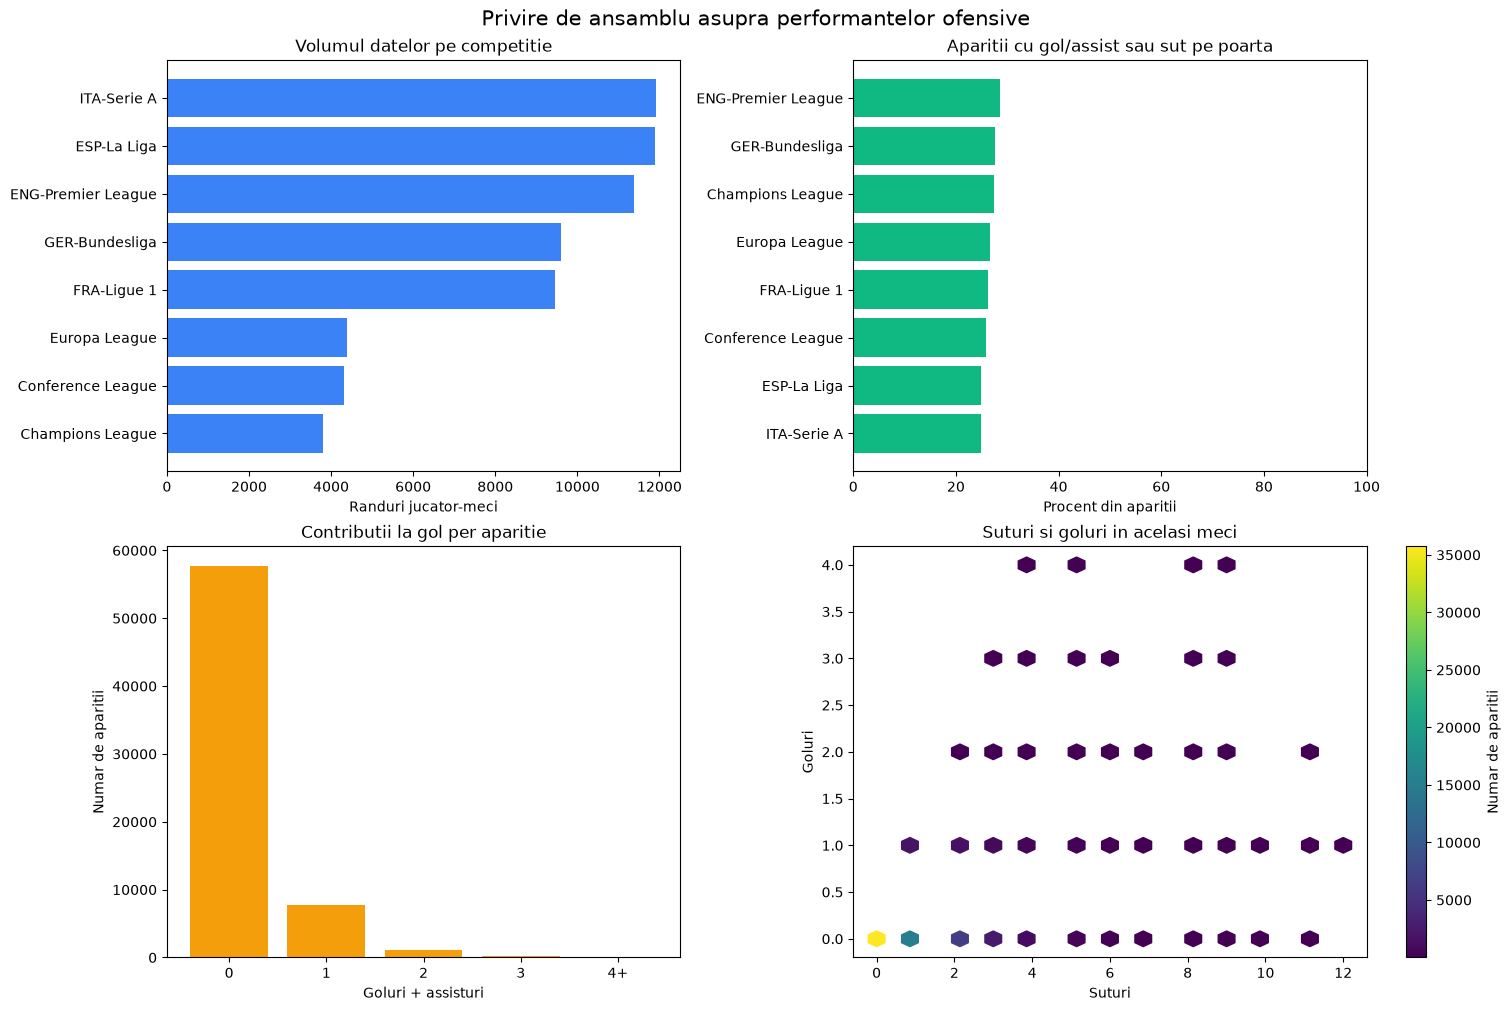

In [14]:
# Pregateste sumarul pentru grafice. O contributie inseamna gol sau assist.
data["goal_contributions"] = data[["goals", "assists"]].sum(axis=1, min_count=2)
data["has_offensive_involvement"] = ((data["goal_contributions"] >= 1) | (data["shots_on_target"] >= 1)).astype(int)
league_summary = (
    data.groupby("league", dropna=False)
    .agg(aparitii=("player", "size"), rata_implicarii_ofensive=("has_offensive_involvement", "mean"))
    .sort_values("aparitii", ascending=False)
)
league_summary["rata_implicarii_ofensive"] = league_summary["rata_implicarii_ofensive"] * 100
display(league_summary.rename(columns={"aparitii": "randuri jucator-meci", "rata_implicarii_ofensive": "% cu gol/assist sau sut pe poarta"}).round(1))

fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)

# Numarul de aparitii pentru fiecare competitie.
plot_counts = league_summary["aparitii"].sort_values()
axes[0, 0].barh(plot_counts.index.astype(str), plot_counts.values, color="#3b82f6")
axes[0, 0].set_title("Volumul datelor pe competitie")
axes[0, 0].set_xlabel("Randuri jucator-meci")
axes[0, 0].set_ylabel("")

# Rata este calculata pe randuri jucator-meci, nu pe jucatori unici.
plot_rates = league_summary["rata_implicarii_ofensive"].sort_values()
axes[0, 1].barh(plot_rates.index.astype(str), plot_rates.values, color="#10b981")
axes[0, 1].set_title("Aparitii cu gol/assist sau sut pe poarta")
axes[0, 1].set_xlabel("Procent din aparitii")
axes[0, 1].set_ylabel("")
axes[0, 1].set_xlim(0, max(100, float(plot_rates.max()) * 1.12))

# Gruparea 4+ pastreaza vizibilitatea valorilor rare.
contribution_counts = data["goal_contributions"].clip(upper=4).value_counts().reindex([0, 1, 2, 3, 4], fill_value=0)
axes[1, 0].bar(["0", "1", "2", "3", "4+"], contribution_counts.values, color="#f59e0b")
axes[1, 0].set_title("Contributii la gol per aparitie")
axes[1, 0].set_xlabel("Goluri + assisturi")
axes[1, 0].set_ylabel("Numar de aparitii")

# Hexbin reduce suprapunerea punctelor atunci cand sunt multe observatii.
shot_goal_data = data[["shots", "goals"]].apply(pd.to_numeric, errors="coerce").dropna()
if not shot_goal_data.empty:
    hb = axes[1, 1].hexbin(shot_goal_data["shots"], shot_goal_data["goals"], gridsize=28, mincnt=1, cmap="viridis")
    fig.colorbar(hb, ax=axes[1, 1], label="Numar de aparitii")
axes[1, 1].set_title("Suturi si goluri in acelasi meci")
axes[1, 1].set_xlabel("Suturi")
axes[1, 1].set_ylabel("Goluri")
fig.suptitle("Privire de ansamblu asupra performantelor ofensive", fontsize=15)
plt.show()

### Corelatii intre statisticile din acelasi meci

Matricea descrie relatiile dintre minute, goluri, assisturi, suturi pe poarta, centrari si alte statistici disponibile. Golurile, assisturile si suturile pe poarta din meciul curent sunt folosite doar la explorare/tinta; predictorii folosesc numai aparitii anterioare si context disponibil inaintea meciului.

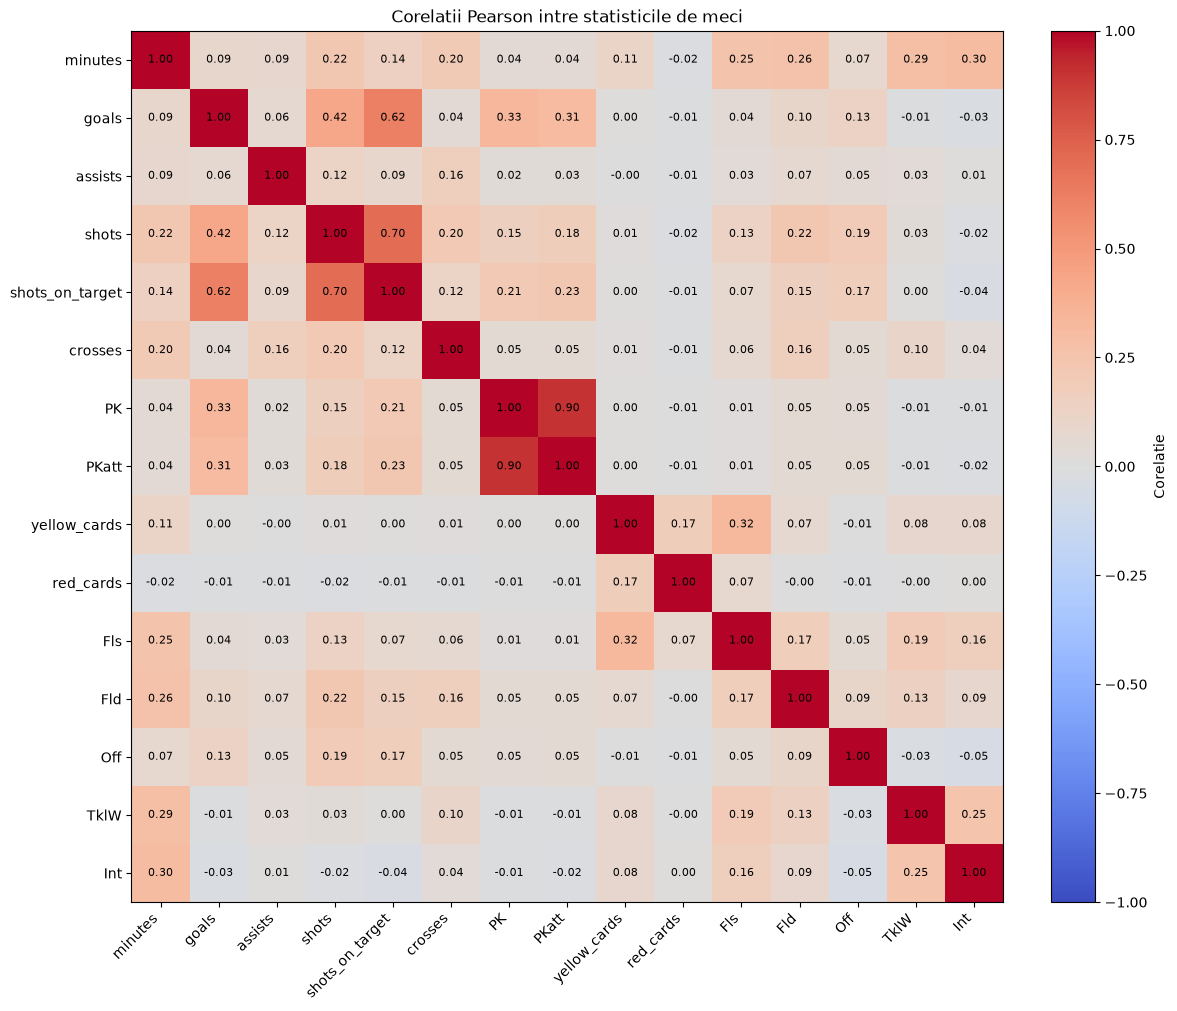

,minutes,goals,assists,shots,shots_on_target,crosses,PK,PKatt,yellow_cards,red_cards,Fls,Fld,Off,TklW,Int
minutes,1.00,0.09,0.09,0.22,0.14,0.20,0.04,0.04,0.11,-0.02,0.25,0.26,0.07,0.29,0.30
goals,0.09,1.00,0.06,0.42,0.62,0.04,0.33,0.31,0.00,-0.01,0.04,0.10,0.13,-0.01,-0.03
assists,0.09,0.06,1.00,0.12,0.09,0.16,0.02,0.03,-0.00,-0.01,0.03,0.07,0.05,0.03,0.01
shots,0.22,0.42,0.12,1.00,0.70,0.20,0.15,0.18,0.01,-0.02,0.13,0.22,0.19,0.03,-0.02
shots_on_target,0.14,0.62,0.09,0.70,1.00,0.12,0.21,0.23,0.00,-0.01,0.07,0.15,0.17,0.00,-0.04
crosses,0.20,0.04,0.16,0.20,0.12,1.00,0.05,0.05,0.01,-0.01,0.06,0.16,0.05,0.10,0.04
PK,0.04,0.33,0.02,0.15,0.21,0.05,1.00,0.90,0.00,-0.01,0.01,0.05,0.05,-0.01,-0.01
PKatt,0.04,0.31,0.03,0.18,0.23,0.05,0.90,1.00,0.00,-0.01,0.01,0.05,0.05,-0.01,-0.02
yellow_cards,0.11,0.00,-0.00,0.01,0.00,0.01,0.00,0.00,1.00,0.17,0.32,0.07,-0.01,0.08,0.08
red_cards,-0.02,-0.01,-0.01,-0.02,-0.01,-0.01,-0.01,-0.01,0.17,1.00,0.07,-0.00,-0.01,-0.00,0.00


In [15]:
correlation_candidates = [
    "minutes", "goals", "assists", "shots", "shots_on_target", "crosses", "PK", "PKatt",
    "yellow_cards", "red_cards", "Fls", "Fld", "Off", "TklW", "Int",
]
available_stats = [column for column in correlation_candidates if column in data.columns]
correlation_data = data[available_stats].apply(pd.to_numeric, errors="coerce")
correlation_data = correlation_data.dropna(axis=1, how="all")
correlation_data = correlation_data.loc[:, correlation_data.nunique(dropna=True) > 1]

if correlation_data.shape[1] < 2:
    print("Nu sunt suficiente statistici numerice pentru matricea de corelatii.")
else:
    correlation_matrix = correlation_data.corr()
    fig, ax = plt.subplots(figsize=(12, 10), constrained_layout=True)
    image = ax.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(correlation_matrix.columns)))
    ax.set_yticks(range(len(correlation_matrix.index)))
    ax.set_xticklabels(correlation_matrix.columns, rotation=45, ha="right")
    ax.set_yticklabels(correlation_matrix.index)
    ax.set_title("Corelatii Pearson intre statisticile de meci")
    for row in range(len(correlation_matrix.index)):
        for column in range(len(correlation_matrix.columns)):
            value = correlation_matrix.iloc[row, column]
            if pd.notna(value):
                ax.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(image, ax=ax, label="Corelatie")
    plt.show()
    display(correlation_matrix.round(2))

## 4. Definirea tintei si crearea caracteristicilor pre-meci

Tinta este 1 daca jucatorul inscrie, ofera assist sau are cel putin un sut pe poarta in meciul curent. Predictorii includ statisticile cumulative din toate aparitiile anterioare, adversarul, competitia, un indicator de absenta raportata si istoricul recent de absente. `expected_minutes_pre_match` este media minutelor din aparitiile anterioare disponibile ale jucatorului.

In [16]:
data = data.dropna(subset=["goals", "assists", "shots_on_target"]).copy()
data["goal_contributions"] = data["goals"] + data["assists"]
data["high_offensive_performance"] = ((data["goal_contributions"] >= 1) | (data["shots_on_target"] >= 1)).astype(int)

past_fields = ["minutes", "goals", "assists", "shots", "shots_on_target", "crosses", "yellow_cards", "red_cards"]
for field in past_fields:
    mean_feature = "expected_minutes_pre_match" if field == "minutes" else f"all_previous_mean_{field}"
    data[mean_feature] = (
        data.groupby("player", sort=False)[field]
        .transform(lambda series: series.shift(1).expanding(min_periods=1).mean())
    )
    data[f"all_previous_sum_{field}"] = (
        data.groupby("player", sort=False)[field]
        .transform(lambda series: series.shift(1).expanding(min_periods=1).sum())
    )

competition_features = pd.get_dummies(data["league"].fillna("unknown"), prefix="competition", dtype=int)
opponent_features = pd.get_dummies(data["opponent"].fillna("unknown"), prefix="opponent", dtype=int)
data = pd.concat([data, competition_features, opponent_features], axis=1)
history_features = [col for col in data.columns if col.startswith("all_previous_")] + ["expected_minutes_pre_match"]
context_features = ["injury_history_matched", "reported_absence_active_pre_match", "reported_absences_last_365d", "days_since_last_reported_absence_end"]
feature_cols = history_features + context_features + list(competition_features.columns) + list(opponent_features.columns)
model_data = data.dropna(subset=["expected_minutes_pre_match", "high_offensive_performance"]).copy()
print("Distributia tintei (0 = fara gol, assist sau sut pe poarta; 1 = cel putin una):")
display(model_data["high_offensive_performance"].value_counts(normalize=True).rename("share").to_frame())
if len(model_data) < MIN_DATA_ROWS:
    raise ValueError(
        f"Criteriul pentru setul de modelare nu este indeplinit: {len(model_data):,} randuri jucator-meci utilizabile; "
        f"sunt necesare cel putin {MIN_DATA_ROWS:,}."
    )
if len(feature_cols) < 10:
    raise ValueError(f"Criteriul caracteristicilor modelului nu este indeplinit: {len(feature_cols)} engineered features; sunt necesare cel putin 10.")
print(f"OK — setul de modelare are {len(model_data):,} randuri utilizabile si {len(feature_cols):,} caracteristici pre-meci")

Distributia tintei (0 = fara gol, assist sau sut pe poarta; 1 = cel putin una):


,share
high_offensive_performance,
0,0.73222
1,0.26778


OK — setul de modelare are 62,611 randuri utilizabile si 187 caracteristici pre-meci


## 5. Impartirea cronologica antrenare/test

Cele mai recente 20% dintre datele distincte sunt pastrate pentru test, separat pe sursa. In configuratia curenta, statisticile de meci provin din FBref; randurile de accidentari Transfermarkt sunt folosite pentru a construi predictorii de disponibilitate. Datele din aceeasi zi raman in acelasi set.

In [17]:
train_parts = []
test_parts = []
for source, source_data in model_data.groupby("source", sort=False):
    source_dates = source_data["match_date"].drop_duplicates().sort_values().reset_index(drop=True)
    split_index = int(len(source_dates) * 0.8)
    if split_index <= 0 or split_index >= len(source_dates):
        raise ValueError(f"Nu sunt suficiente date distincte pentru impartirea cronologica a sursei {source}.")
    split_date = source_dates.iloc[split_index]
    train_parts.append(source_data[source_data["match_date"] < split_date].copy())
    test_parts.append(source_data[source_data["match_date"] >= split_date].copy())

train = pd.concat(train_parts, ignore_index=True)
test = pd.concat(test_parts, ignore_index=True)
X_train, X_test = train[feature_cols], test[feature_cols]
y_train = train["high_offensive_performance"]
y_test = test["high_offensive_performance"]
if y_train.nunique() < 2 or y_test.nunique() < 2:
    raise ValueError("Impartirea cronologica nu contine ambele clase in antrenare si test.")
print(f"Randuri de antrenare: {len(train):,}")
print(f"Randuri de test: {len(test):,}")
print("Randuri de test pe sursa:")
display(test.groupby("source").size().rename("randuri").to_frame())


Randuri de antrenare: 53,053
Randuri de test: 9,558
Randuri de test pe sursa:


,randuri
source,
fbref,9558


## 6. Antrenarea si compararea modelelor

Sunt comparate regresia logistica si padurea aleatoare. Valorile lipsa din predictorii numerici sunt completate cu mediana; regresia logistica scaleaza caracteristicile numerice. Comparatia include acuratete, precizie, recall, F1, ROC AUC si media preciziei (PR AUC).

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Regresie logistica": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42)),
    ]),
    "Padure aleatoare": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=400, min_samples_leaf=3, class_weight="balanced",
            random_state=42, n_jobs=-1,
        )),
    ]),
}

results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    predictions[name] = (predicted, probability)
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, predicted),
        "precision": precision_score(y_test, predicted, zero_division=0),
        "recall": recall_score(y_test, predicted, zero_division=0),
        "f1": f1_score(y_test, predicted, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probability),
        "average_precision": average_precision_score(y_test, probability),
    })

comparison = pd.DataFrame(results).set_index("model").sort_values("average_precision", ascending=False)
display(comparison.round(3))

,accuracy,precision,recall,f1,roc_auc,average_precision
model,,,,,,
Regresie logistica,0.696,0.456,0.661,0.540,0.750,0.525
Padure aleatoare,0.690,0.447,0.645,0.528,0.746,0.514


## 7. Evaluarea modelelor si salvarea rezultatelor

Modelul ales dupa media preciziei este evaluat global si separat pe competitie. Fisierul de predictii pastreaza competitia, echipa/adversarul, estimarea minutelor, indicatorii Transfermarkt si tinta observata. Rezultatele se salveaza in `data/processed/`.

In [19]:
best_name = comparison.index[0]
best_model = models[best_name]
best_pred, best_probability = predictions[best_name]
print("Selectat dupa media preciziei:", best_name)
print("Matrice de confuzie (randuri = real [0, 1], coloane = prezis [0, 1]):")
print(confusion_matrix(y_test, best_pred))

comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", encoding="utf-8-sig")
test_results = test[["source", "league", "player", "team", "opponent", "match_date", "goals", "assists", "shots_on_target", "expected_minutes_pre_match", "injury_history_matched", "reported_absence_active_pre_match", "reported_absences_last_365d", "high_offensive_performance"]].copy()
test_results["predicted_high_performance"] = best_pred
test_results["predicted_probability"] = best_probability
test_results.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False, encoding="utf-8-sig")
competition_scores = []
test_predictions = pd.Series(best_pred, index=test.index)
test_probabilities = pd.Series(best_probability, index=test.index)
for competition in test["league"].dropna().unique():
    positions = test.index[test["league"].eq(competition)]
    source_actual = y_test.loc[positions]
    source_pred = test_predictions.loc[positions]
    source_prob = test_probabilities.loc[positions]
    competition_scores.append({
        "competition": competition,
        "rows": len(positions),
        "precision": precision_score(source_actual, source_pred, zero_division=0),
        "recall": recall_score(source_actual, source_pred, zero_division=0),
        "f1": f1_score(source_actual, source_pred, zero_division=0),
        "average_precision": average_precision_score(source_actual, source_prob),
    })
competition_comparison = pd.DataFrame(competition_scores).set_index("competition")
display(competition_comparison.round(3))
competition_comparison.to_csv(OUTPUT_DIR / "competition_metrics.csv", encoding="utf-8-sig")
print("Salvat:", OUTPUT_DIR / "model_comparison.csv")
print("Salvat:", OUTPUT_DIR / "test_predictions.csv")
print("Salvat:", OUTPUT_DIR / "competition_metrics.csv")

Selectat dupa media preciziei: Regresie logistica
Matrice de confuzie (randuri = real [0, 1], coloane = prezis [0, 1]):
[[4956 2029]
 [ 872 1701]]


,rows,precision,recall,f1,average_precision
competition,,,,,
Europa League,274,0.400,0.685,0.505,0.477
ENG-Premier League,1709,0.488,0.747,0.591,0.587
GER-Bundesliga,1438,0.472,0.710,0.567,0.561
ITA-Serie A,1925,0.405,0.591,0.481,0.470
FRA-Ligue 1,1511,0.457,0.620,0.526,0.501
ESP-La Liga,2170,0.468,0.622,0.534,0.520
Conference League,269,0.465,0.676,0.551,0.487
Champions League,262,0.432,0.739,0.545,0.568


Salvat: /Users/laur/Master Data Science/sem1/IAPD/IAPD_project/data/processed/model_comparison.csv
Salvat: /Users/laur/Master Data Science/sem1/IAPD/IAPD_project/data/processed/test_predictions.csv
Salvat: /Users/laur/Master Data Science/sem1/IAPD/IAPD_project/data/processed/competition_metrics.csv


## Interpretare si limitari

- Tinta extinsa surprinde contributiile directe si suturile cadrate, dar nu toate formele de creatie ofensiva, precum pasele-cheie sau progresia mingii.
- Adversarul este reprezentat prin identitatea echipei; modelul nu estimeaza separat forta defensiva a adversarului.
- Minutele estimate sunt media istorica a jucatorului, nu o estimare bazata pe primul 11 confirmat.
- Transfermarkt contine absente raportate, nu fise medicale complete. Potrivirea dupa nume este incompleta, iar lipsa unei inregistrari nu confirma ca jucatorul era apt. Datele nu includ momentul publicarii raportului.
- FBref contine aici doar jucatorii cu minute jucate; modelul estimeaza performanta conditionat de aparitie si nu prezice lista completa a jucatorilor indisponibili.
- Testarea cronologica se face in cadrul sezonului 2023/24; pentru generalizare la sezonul urmator este nevoie de evaluare pe meciuri din acel sezon.